# 03 · Kiểm định giả thuyết

Notebook này kiểm tra 4 giả thuyết rút ra từ EDA (`02_eda.ipynb`, mục 6).

**So sánh chính:** Barca 2018-21 (102 trận, 31–33 tuổi) và PSG 2021-23 (58 trận, 34–35 tuổi). Đây là giai đoạn ở
Barca gần tuổi với PSG nhất, nên so sánh công bằng hơn so với cả sự nghiệp ở Barca. Riêng H4 dùng toàn bộ 577 trận.

| # | Giả thuyết (H₁) | Phương pháp |
|---|---|---|
| H1 | Ở PSG Messi có **ít cơ hội tốt hơn**: npxG/90' khác Barca | Permutation test + bootstrap |
| H2 | Ở PSG Messi **sút ít hơn**: cú sút/90' khác Barca | Hồi quy Poisson |
| H3 | Ở PSG Messi **dứt điểm kém hơn** ở cùng mức xG | Hồi quy logistic + mô phỏng |
| H4 | Mức giảm ở PSG **không chỉ do tuổi** | Hồi quy Poisson có biến tuổi |

**Cách đọc kết quả**

- **H₀ (giả thuyết không):** không có khác biệt. Kiểm định đo xem dữ liệu có đủ "lạ" để bác bỏ H₀ hay không.
- **p-value:** xác suất thấy khác biệt lớn như vậy (hoặc lớn hơn) *nếu H₀ đúng*. p < 0,05 thì bác bỏ H₀.
- **Effect size và khoảng tin cậy 95% (CI):** p-value chỉ cho biết *có* khác biệt hay không; effect size cho biết
  khác biệt *lớn bao nhiêu*. Mọi effect ở đây là **tỉ số PSG ÷ Barca**: 1 = như nhau, 0,7 = PSG thấp hơn 30%.
  Nếu CI chứa 1 thì chưa thể nói hai giai đoạn khác nhau.
- **Hiệu chỉnh Holm:** làm 4 kiểm định thì khả năng "may mắn" có ít nhất một p < 0,05 tăng lên. Holm điều chỉnh
  p-value để tổng xác suất kết luận sai vẫn ≤ 5%. Kết luận cuối cùng dựa trên `p_holm` (mục 5).

## 0. Thiết lập

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(
    folder for folder in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (folder / "src" / "eda_utils.py").exists()
)
sys.path.insert(0, str(PROJECT_ROOT))

from src.eda_utils import (
    PERIOD_COLORS, LEAGUE_COLORS, GOAL_COLOR, MISS_COLOR, TEXT_SECONDARY, AXIS_COLOR,
    apply_plot_style, load_data,
)
from src.hypothesis_tests import (
    ALPHA, BASELINE_PERIOD, PSG_PERIOD, AGE_CENTER,
    main_comparison, non_penalty_shots,
    permutation_test_rate_ratio, bootstrap_rate_ratio_ci, compare_shot_xg,
    fit_count_model, exponentiated_effect, add_age_terms,
    fit_finishing_model, simulate_goals_from_xg, finishing_vs_xg,
    result_row, add_holm_and_conclusion, format_effect,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)
apply_plot_style()

RESULTS_FILE = PROJECT_ROOT / "data" / "results" / "hypothesis_results.csv"

matches, shots = load_data(PROJECT_ROOT)
compared_matches = main_comparison(matches)                       # Barca 2018-21 + PSG 2021-23
compared_np_shots = non_penalty_shots(main_comparison(shots))      # same periods, no penalties

print(compared_matches.groupby("period", observed=True).agg(matches=("match_id", "size"),
                                                            minutes=("minutes_played", "sum")))
results = []   # one row per hypothesis, filled in below

               matches  minutes
period                         
Barca 2018-21      102     8616
PSG 2021-23         58     4991


## 1. H1 · Ở PSG Messi có ít cơ hội tốt hơn

- **H₀:** npxG/90' ở PSG bằng Barca 2018-21.
- **H₁:** npxG/90' ở PSG khác Barca 2018-21.

**Phương pháp.** npxG mỗi trận không phải số đếm và phân phối rất lệch, nên dùng **permutation test**, một kiểm
định không cần giả định phân phối: trộn ngẫu nhiên nhãn "PSG / Barca" giữa các trận 5.000 lần, xem tỉ số npxG/90'
thu được khi nhãn bị trộn có thường xuyên cực đoan như tỉ số thật không. Khoảng tin cậy lấy bằng **bootstrap**
(lấy mẫu lại các trận trong từng giai đoạn).

**Kiểm định phụ.** npxG/90' = cú sút/90' × npxG/cú sút. Để biết *chất lượng từng cơ hội* có giảm không, so sánh xG
của từng cú sút bằng **Mann–Whitney U** (so sánh hai phân phối, không cần giả định phân phối chuẩn).

In [2]:
npxg_ratio, h1_p_value = permutation_test_rate_ratio(compared_matches, "npxg", "minutes_played")
h1_ci = bootstrap_rate_ratio_ci(compared_matches, "npxg", "minutes_played")
h1_effect = {"estimate": npxg_ratio, "ci_low": h1_ci[0], "ci_high": h1_ci[1], "p_value": h1_p_value}
print("Tỉ số npxG/90' (PSG ÷ Barca 18-21):", format_effect(h1_effect))

shot_xg = compare_shot_xg(compared_np_shots)
print(f"xG trung vị mỗi cú sút: PSG {shot_xg['median_psg']:.3f} | Barca 18-21 {shot_xg['median_baseline']:.3f} "
      f"| Mann-Whitney p = {shot_xg['p_value']:.3f}")

results.append(result_row("H1", "Ít cơ hội tốt hơn", "Permutation test",
                          "Tỉ số npxG/90'", h1_effect))

Tỉ số npxG/90' (PSG ÷ Barca 18-21): 0.81 (95% CI 0.64–1.02), p = 0.0634
xG trung vị mỗi cú sút: PSG 0.068 | Barca 18-21 0.064 | Mann-Whitney p = 0.035


**Kết quả H1**

- npxG/90' ở PSG bằng **0,81 lần** Barca 2018-21, CI 0,64–1,02, p = 0,063. CI chứa 1, nên **chưa đủ bằng chứng
  bác bỏ H₀**.
- Từng cú sút ở PSG **không kém hơn**, thậm chí xG trung vị nhỉnh hơn một chút (0,068 so với 0,064, p = 0,035).
  Nếu npxG/90' có giảm thì là do **số cú sút ít đi** (H2), không phải do cơ hội kém chất lượng hơn.
- Lưu ý: "không có ý nghĩa thống kê" **không có nghĩa là bằng nhau**. CI cho thấy npxG/90' ở PSG có thể thấp hơn
  tới 36% hoặc tương đương Barca; mẫu 58 trận chưa đủ để phân biệt.

## 2. H2 · Ở PSG Messi sút ít hơn

- **H₀:** cú sút/90' ở PSG bằng Barca 2018-21.
- **H₁:** cú sút/90' ở PSG khác Barca 2018-21.

**Phương pháp.** Số cú sút mỗi trận là **số đếm** (0, 1, 2, …), nên dùng **hồi quy Poisson**:
`shots ~ is_psg`, với `log(phút thi đấu)` làm *offset*. Offset nghĩa là mô hình so sánh **số cú sút trên mỗi phút**,
nên trận đá 30 phút và trận đá 90 phút được tính công bằng. `exp(hệ số is_psg)` là **tỉ số cú sút/90'** giữa PSG và Barca.

Poisson giả định phương sai bằng trung bình. Nếu dữ liệu phân tán hơn (dispersion > 1,5), hàm tự chuyển sang
**Negative Binomial**.

In [3]:
shots_model, shots_model_name, shots_dispersion = fit_count_model(compared_matches, "shots ~ is_psg")
h2_effect = exponentiated_effect(shots_model, "is_psg")
print(f"Mô hình: {shots_model_name} (dispersion = {shots_dispersion:.2f})")
print("Tỉ số cú sút/90' (PSG ÷ Barca 18-21):", format_effect(h2_effect, 3))

# Kiểm tra chéo bằng permutation test, không cần giả định Poisson
_, shots_permutation_p = permutation_test_rate_ratio(compared_matches, "shots", "minutes_played")
print(f"Permutation test: p = {shots_permutation_p:.4f}")

results.append(result_row("H2", "Sút ít hơn", f"Hồi quy {shots_model_name}, offset log(phút)",
                          "Tỉ số cú sút/90'", h2_effect))

Mô hình: Poisson (dispersion = 1.01)
Tỉ số cú sút/90' (PSG ÷ Barca 18-21): 0.717 (95% CI 0.612–0.839), p = 0.0000
Permutation test: p = 0.0002


**Kết quả H2**

- Ở PSG Messi sút bằng **0,72 lần** Barca 2018-21, tức **ít hơn khoảng 28%**. CI 0,61–0,84, p < 0,0001.
  **Bác bỏ H₀.**
- Dispersion ≈ 1,0, nên mô hình Poisson phù hợp. Permutation test (không cần giả định Poisson) cho kết luận giống hệt
  (p ≈ 0,0002).
- Đây là thay đổi rõ ràng nhất về **khối lượng** trong lối chơi của Messi ở PSG.

## 3. H3 · Ở PSG Messi dứt điểm kém hơn ở cùng mức xG

- **H₀:** ở cùng một mức xG, xác suất ghi bàn ở PSG bằng Barca 2018-21.
- **H₁:** ở cùng một mức xG, xác suất ghi bàn ở PSG khác Barca 2018-21.

**Phương pháp.** **Hồi quy logistic** trên từng cú sút không phải penalty: `goal ~ logit(xG) + is_psg`.

- `logit(xG)` đưa **độ khó của cú sút** vào mô hình, nên `is_psg` chỉ còn đo **khả năng dứt điểm**.
- `exp(hệ số is_psg)` là **odds ratio**: ở cùng mức xG, odds ghi bàn ở PSG bằng bao nhiêu lần Barca.
- Các cú sút trong cùng một trận không độc lập (cùng đối thủ, cùng phong độ), nên sai số chuẩn được tính
  **theo cụm từng trận** (*clustered standard errors*).

In [4]:
finishing_model = fit_finishing_model(compared_np_shots)
h3_effect = exponentiated_effect(finishing_model, "is_psg")
print("Odds ratio ghi bàn ở cùng xG (PSG ÷ Barca 18-21):", format_effect(h3_effect, 3))

baseline_multiplier = np.exp(finishing_model.params["Intercept"])
psg_multiplier = np.exp(finishing_model.params["Intercept"] + finishing_model.params["is_psg"])
print(f"Hệ số logit(xG) = {finishing_model.params['logit_xg']:.2f} (≈ 1 nghĩa là xG của StatsBomb xếp hạng cơ hội đúng)")
print(f"Odds ghi bàn so với kỳ vọng xG (tính tại xG = 0,5; vì hệ số logit(xG) ≈ 1 nên gần đúng ở mọi mức xG): "
      f"Barca 18-21 × {baseline_multiplier:.2f} | PSG × {psg_multiplier:.2f}")

results.append(result_row("H3", "Dứt điểm kém hơn so với xG", "Hồi quy logistic, SE cluster theo trận",
                          "Odds ratio ghi bàn ở cùng xG", h3_effect))

Odds ratio ghi bàn ở cùng xG (PSG ÷ Barca 18-21): 0.489 (95% CI 0.292–0.819), p = 0.0065
Hệ số logit(xG) = 1.09 (≈ 1 nghĩa là xG của StatsBomb xếp hạng cơ hội đúng)
Odds ghi bàn so với kỳ vọng xG (tính tại xG = 0,5; vì hệ số logit(xG) ≈ 1 nên gần đúng ở mọi mức xG): Barca 18-21 × 2.25 | PSG × 1.10


**Mô phỏng: một cầu thủ dứt điểm "trung bình" sẽ ghi bao nhiêu bàn?**

Mỗi cú sút được coi là một lần tung đồng xu với xác suất ghi bàn đúng bằng xG của nó. Lặp lại 10.000 lần cho ra phân
phối số bàn mà một cầu thủ dứt điểm đúng bằng xG sẽ ghi được từ chính những cú sút đó. So sánh số bàn thật của Messi
với phân phối này.

,shots,goals,npxg,goals_minus_npxg,share_sims_at_least_actual,share_sims_at_most_actual
period,,,,,,
Barca 2004-18,1768,333,216.024,116.976,0.000,1.000
Barca 2018-21,510,79,49.518,29.482,0.000,1.000
PSG 2021-23,218,22,23.130,-1.130,0.635,0.457


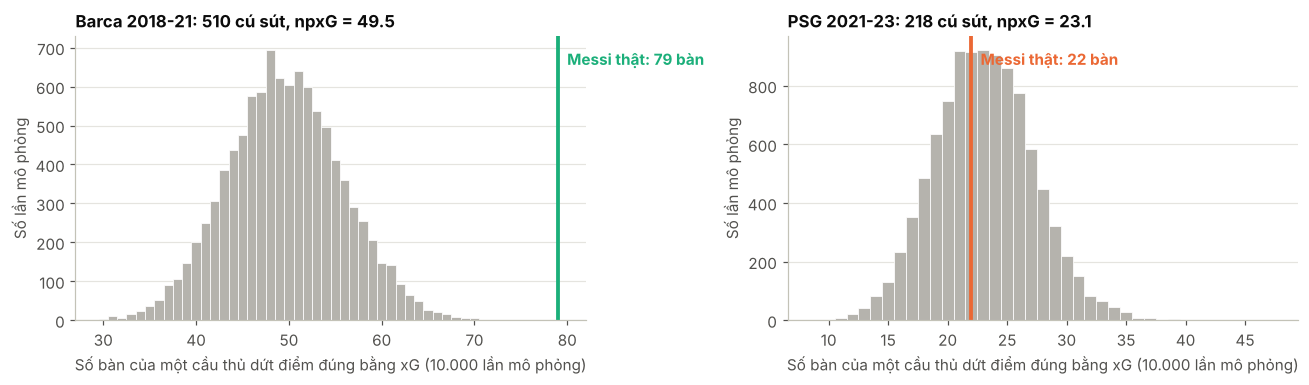

In [5]:
finishing_table = finishing_vs_xg(non_penalty_shots(shots))
display(finishing_table)

np_shots_all = non_penalty_shots(shots)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
for ax, period in zip(axes, [BASELINE_PERIOD, PSG_PERIOD]):
    period_shots = np_shots_all[np_shots_all["period"] == period]
    simulated = simulate_goals_from_xg(period_shots["xg"])
    actual = int(period_shots["is_goal"].sum())
    bins = np.arange(simulated.min(), max(simulated.max(), actual) + 2) - 0.5
    ax.hist(simulated, bins=bins, color=MISS_COLOR, edgecolor="white", linewidth=0.5)
    ax.axvline(actual, color=PERIOD_COLORS[period], linewidth=2.5)
    ax.annotate(f"Messi thật: {actual} bàn", xy=(actual, ax.get_ylim()[1] * 0.9), xytext=(6, 0),
                textcoords="offset points", color=PERIOD_COLORS[period], fontweight="bold")
    ax.set_title(f"{period}: {len(period_shots)} cú sút, npxG = {period_shots['xg'].sum():.1f}")
    ax.set_xlabel("Số bàn của một cầu thủ dứt điểm đúng bằng xG (10.000 lần mô phỏng)")
    ax.set_ylabel("Số lần mô phỏng")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

**Kết quả H3**

- Ở cùng mức xG, odds ghi bàn của Messi ở PSG chỉ bằng **0,49 lần** Barca 2018-21. CI 0,29–0,82, p = 0,007.
  **Bác bỏ H₀.**
- Ở Barca 2018-21, odds ghi bàn của Messi cao gấp khoảng **2,25 lần** mức xG dự đoán. Ở PSG, con số này chỉ còn
  khoảng **1,1 lần**, gần như đúng bằng xG. (Con số tính tại xG = 0,5; vì hệ số logit(xG) ≈ 1 nên gần đúng ở mọi
  mức xG.)
- Mô phỏng cho cùng câu chuyện: ở Barca 2018-21, **không lần mô phỏng nào trong 10.000 lần** đạt được 79 bàn như
  Messi. Ở PSG, 22 bàn nằm ngay giữa phân phối (khoảng 46% số lần mô phỏng ghi ≤ 22 bàn).
- Diễn giải: Messi ở PSG **không dứt điểm tệ**. Anh dứt điểm **như một cầu thủ trung bình**, và đã mất đi khả năng
  ghi vượt xG vốn là điểm đặc biệt nhất của anh ở Barca.

## 4. H4 · Mức giảm ở PSG không chỉ do tuổi

- **H₀:** sau khi tính đến tuổi, bàn không pen/90' ở PSG bằng mức mà đường tuổi ở Barca dự đoán.
- **H₁:** sau khi tính đến tuổi, PSG vẫn khác.

**Phương pháp.** Hồi quy Poisson trên **toàn bộ 577 trận**:
`non_penalty_goals ~ tuổi + tuổi² + is_psg`, offset `log(phút)`. `tuổi²` cho phép đường tuổi cong (tăng rồi giảm).
`exp(hệ số is_psg)` là mức PSG thấp hơn/cao hơn *sau khi đã tính đến tuổi*.

⚠️ **Hạn chế quan trọng:** Messi chỉ ở tuổi 34–35 khi chơi cho PSG. "Đá cho PSG" và "34–35 tuổi" **trùng nhau hoàn
toàn**, nên mô hình phải *đoán* đường tuổi sẽ đi thế nào sau 33 tuổi. Vì vậy cần thử thêm một dạng đường tuổi khác
(**phân tích độ nhạy**): nếu kết luận thay đổi theo cách vẽ đường tuổi, thì dữ liệu chưa đủ để trả lời H4.

In [6]:
age_matches = add_age_terms(matches)

age_specifications = {
    "Tuổi + tuổi² (chính)": "non_penalty_goals ~ age_c + I(age_c**2) + is_psg",
    "Chỉ tuổi (độ nhạy)": "non_penalty_goals ~ age_c + is_psg",
}
age_models = {}
for label, formula in age_specifications.items():
    model, model_name, dispersion = fit_count_model(age_matches, formula)
    age_models[label] = model
    print(f"{label:24s} [{model_name}, dispersion {dispersion:.2f}]  "
          f"tỉ số PSG: {format_effect(exponentiated_effect(model, 'is_psg'), 3)}")

h4_effect = exponentiated_effect(age_models["Tuổi + tuổi² (chính)"], "is_psg")
results.append(result_row("H4", "Không chỉ do tuổi", "Hồi quy Poisson, tuổi + tuổi², offset log(phút)",
                          "Tỉ số bàn không pen/90' sau khi tính tuổi", h4_effect))

# Bổ sung: số cú sút sau khi tính tuổi
shots_age_model, name, _ = fit_count_model(age_matches, "shots ~ age_c + I(age_c**2) + is_psg")
print(f"\nBổ sung, cú sút/90' sau khi tính tuổi + tuổi² [{name}]: "
      f"{format_effect(exponentiated_effect(shots_age_model, 'is_psg'), 3)}")

Tuổi + tuổi² (chính)     [Poisson, dispersion 1.16]  tỉ số PSG: 0.678 (95% CI 0.385–1.195), p = 0.1794
Chỉ tuổi (độ nhạy)       [Poisson, dispersion 1.07]  tỉ số PSG: 0.405 (95% CI 0.254–0.645), p = 0.0001

Bổ sung, cú sút/90' sau khi tính tuổi + tuổi² [Poisson]: 0.776 (95% CI 0.636–0.946), p = 0.0121


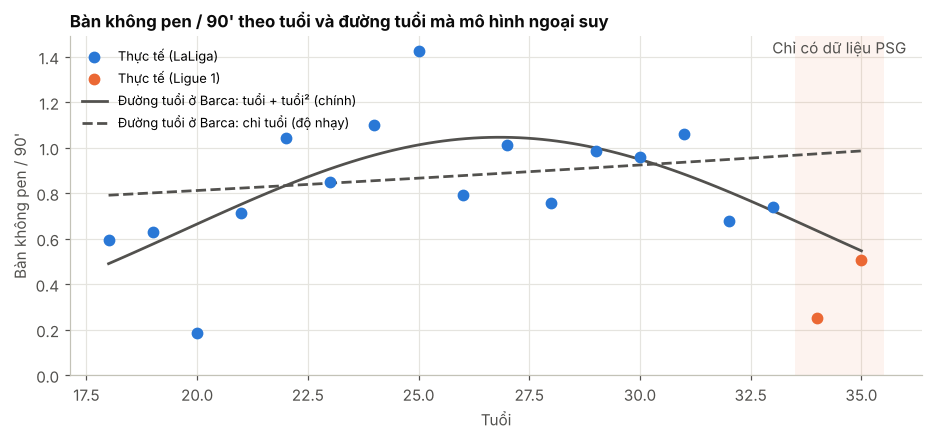

In [7]:
# Đường tuổi mà mỗi mô hình "đoán" cho Messi nếu vẫn ở Barca (is_psg = 0)
by_age = (age_matches.groupby(["age", "competition"])
          .agg(np_goals=("non_penalty_goals", "sum"), minutes=("minutes_played", "sum")).reset_index())
by_age = by_age[by_age["minutes"] >= 900]
by_age["np_goals_p90"] = by_age["np_goals"] / by_age["minutes"] * 90

ages = np.linspace(age_matches["age"].min() + 1, age_matches["age"].max(), 100)
grid = pd.DataFrame({"age_c": ages - AGE_CENTER, "is_psg": 0})

fig, ax = plt.subplots(figsize=(10, 4))
for competition, group in by_age.groupby("competition"):
    ax.scatter(group["age"], group["np_goals_p90"], s=45, color=LEAGUE_COLORS[competition], zorder=3,
               label=f"Thực tế ({competition})")
for (label, model), style in zip(age_models.items(), ["-", "--"]):
    predicted = model.predict(grid, offset=np.log(np.full(len(grid), 90.0)))
    ax.plot(ages, predicted, linestyle=style, color=TEXT_SECONDARY, linewidth=1.8,
            label=f"Đường tuổi ở Barca: {label.lower()}")
ax.axvspan(33.5, 35.5, color=LEAGUE_COLORS["Ligue 1"], alpha=0.08, linewidth=0)
ax.annotate("Chỉ có dữ liệu PSG", xy=(34.5, ax.get_ylim()[1] * 0.95), ha="center", color=TEXT_SECONDARY)
ax.set_title("Bàn không pen / 90' theo tuổi và đường tuổi mà mô hình ngoại suy")
ax.set_xlabel("Tuổi")
ax.set_ylabel("Bàn không pen / 90'")
ax.set_ylim(bottom=0)
ax.legend(loc="upper left", fontsize=8.5)
plt.show()

**Kết quả H4**

- Mô hình chính (tuổi + tuổi²): PSG bằng **0,68 lần** mức đường tuổi dự đoán, CI 0,39–1,20, p = 0,18.
  **Chưa đủ bằng chứng bác bỏ H₀.**
- Phân tích độ nhạy (chỉ tuổi, đường thẳng): PSG bằng **0,41 lần**, p = 0,0001, tức là có ý nghĩa rõ ràng.
- Biểu đồ giải thích vì sao hai cách cho hai kết quả khác nhau: đường cong (tuổi²) tự "bẻ xuống" sau 33 tuổi và gán
  phần lớn mức giảm cho tuổi; đường thẳng thì không. Vì không có dữ liệu Messi 34–35 tuổi ở Barca, **không cách nào
  biết đường nào đúng**.
- **Kết luận: dữ liệu không tách được tác động của tuổi khỏi tác động của việc chuyển sang PSG.** Đây là hạn chế của
  dữ liệu, không phải của phương pháp, và nên được ghi rõ trong báo cáo.
- Một điểm đáng chú ý: **số cú sút** vẫn thấp hơn rõ rệt ngay cả sau khi tính tuổi + tuổi² (0,78 lần, p = 0,012).
  Nói cách khác, việc Messi sút ít hơn ở PSG khó giải thích chỉ bằng tuổi. Đây là kết quả bổ sung, không nằm trong
  4 kiểm định chính.

> **Cần sửa ở EDA và dashboard:** câu "tuổi không giải thích hết" ở mục 6 của `02_eda.ipynb` nói quá mạnh. Nên đổi
> thành: "Không tách được tuổi khỏi việc chuyển sang PSG; riêng số cú sút vẫn giảm sau khi tính tuổi".

## 5. Tổng hợp kết quả

p-value của 4 kiểm định chính được hiệu chỉnh Holm. Bảng được lưu ra `data/results/hypothesis_results.csv` để dùng cho
trang **Giả thuyết** trong Power BI và README.

In [8]:
summary = add_holm_and_conclusion(pd.DataFrame(results))
display(summary[["hypothesis", "claim", "effect", "estimate", "ci_low", "ci_high", "p_value", "p_holm", "conclusion"]])

RESULTS_FILE.parent.mkdir(parents=True, exist_ok=True)
summary.to_csv(RESULTS_FILE, index=False)
print(f"Đã lưu: {RESULTS_FILE.relative_to(PROJECT_ROOT)}")

,hypothesis,claim,effect,estimate,ci_low,ci_high,p_value,p_holm,conclusion
0,H1,Ít cơ hội tốt hơn,Tỉ số npxG/90',0.806,0.643,1.022,6.339e-02,1.268e-01,Chưa đủ bằng chứng bác bỏ H0
1,H2,Sút ít hơn,Tỉ số cú sút/90',0.717,0.612,0.839,3.598e-05,1.439e-04,Bác bỏ H0 (PSG thấp hơn)
2,H3,Dứt điểm kém hơn so với xG,Odds ratio ghi bàn ở cùng xG,0.489,0.292,0.819,6.510e-03,1.953e-02,Bác bỏ H0 (PSG thấp hơn)
3,H4,Không chỉ do tuổi,Tỉ số bàn không pen/90' sau khi tính tuổi,0.678,0.385,1.195,1.794e-01,1.794e-01,Chưa đủ bằng chứng bác bỏ H0


Đã lưu: data/results/hypothesis_results.csv


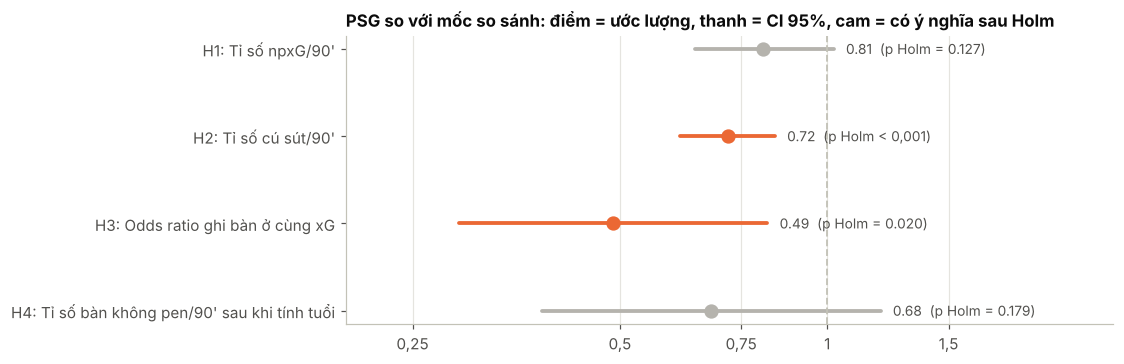

In [9]:
# Forest plot: mọi effect là tỉ số PSG ÷ mốc so sánh; 1 = không khác biệt
fig, ax = plt.subplots(figsize=(9, 3.4))
positions = np.arange(len(summary))[::-1]
for y, (_, row) in zip(positions, summary.iterrows()):
    color = PERIOD_COLORS[PSG_PERIOD] if row["significant"] else MISS_COLOR
    ax.plot([row["ci_low"], row["ci_high"]], [y, y], color=color, linewidth=2.5, solid_capstyle="round")
    ax.scatter(row["estimate"], y, s=70, color=color, zorder=3)
    p_text = "< 0,001" if row["p_holm"] < 0.001 else f"= {row['p_holm']:.3f}"
    ax.annotate(f"{row['estimate']:.2f}  (p Holm {p_text})", xy=(row["ci_high"], y),
                xytext=(8, 0), textcoords="offset points", va="center", color=TEXT_SECONDARY, fontsize=9)
ax.axvline(1, color=AXIS_COLOR, linewidth=1.2, linestyle="--")
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks([0.25, 0.5, 0.75, 1, 1.5], ["0,25", "0,5", "0,75", "1", "1,5"])
ax.set_xlim(0.2, 2.6)
ax.set_yticks(positions, [f"{h}: {e}" for h, e in zip(summary["hypothesis"], summary["effect"])])
ax.grid(axis="y", visible=False)
ax.set_title("PSG so với mốc so sánh: điểm = ước lượng, thanh = CI 95%, cam = có ý nghĩa sau Holm")
plt.show()

### Kết luận

**Vì sao Messi ghi ít bàn hơn ở PSG?** Có hai nguyên nhân được dữ liệu ủng hộ:

1. **Anh sút ít hơn (H2):** ít hơn khoảng 28% số cú sút/90'. Kết quả chắc chắn, và vẫn đúng ngay cả khi tính đến tuổi.
2. **Anh mất khả năng ghi vượt xG (H3):** ở Barca 2018-21 anh biến cơ hội thành bàn tốt gấp đôi mức trung bình; ở PSG
   anh chỉ dứt điểm đúng bằng xG.

Hai điều **không** được khẳng định:

- **Cơ hội kém chất lượng hơn (H1):** chưa đủ bằng chứng. Mỗi cú sút ở PSG thậm chí còn là cơ hội tốt hơn một chút.
- **Chỉ do tuổi hay không (H4):** dữ liệu không trả lời được, vì 34–35 tuổi chỉ xuất hiện ở PSG.

**Hạn chế**

- Mẫu PSG nhỏ (58 trận, 218 cú sút), nên lực kiểm định thấp, nhất là với H1.
- Số phút bị giới hạn ở 90, không tính bù giờ (xem ghi chú dữ liệu trong EDA).
- Thiếu một trận ở Barca (26/09/2007) do StatsBomb Open Data không có.
- Các yếu tố như vai trò chiến thuật, đồng đội (Mbappé, Neymar) hay chấn thương không có trong dữ liệu, nên không
  kiểm tra được.

**Bước tiếp theo:** mô hình xG riêng của Messi (bước 6) là một cách khác để kiểm tra H3: huấn luyện trên các cú sút ở
Barca, dự đoán cho các cú sút ở PSG, rồi so sánh với số bàn thực tế.